# UNIDAD 1 - Estructura cristalina y Enlace atómico

#### Dr. José Manuel López López - Feb. 26

## 1. Concepto de cristal

### Materia condensada

#### Materia blanda (*soft matter*)

La materia condensada blanda (*soft matter*) puede deformarse fácilmente, involucra energías del orden de la *energía térmica* $k_B T$ y no suele necesitar una descripción cuántica. Ejemplos: *líquidos* clásicos, *dispersiones coloidales*, *polímeros*, *geles*, *espumas*, *cristales líquidos*, *emulsiones*, etc.

La siguiente microfotografía de *microscopio de transmisión electrónica* (TEM) muestra partículas coloidales de poliestireno en agua con un diámetro de $550\,\text{nm}$:

![imagen TEM de coloide](images/TEM_coloide.png)

> Microfotografía TEM de nanopartículas de poliestireno. Fuente: J. M. López-López, *Electrostatic heteroaggregation processes arising in two-component colloidal dispersions*, tesis doctoral (2006), Universidad de Granada.

#### Materia dura (*hard matter*)

La materia condensada dura (*hard matter*) requiere energías muy superiores a la térmica para deformarse y no puede entenderse sin estudiar sus *propiedades cuánticas*. Estudia principalmente los *sólidos cristalinos* (metales, aislantes y semiconductores), pero también otros sólidos no cristalinos como los *cuasicristales*, los *vidrios* y otros *sólidos amorfos*.

### Sólidos cristalinos

#### Granos cristalinos

En los **sólidos cristalinos** los átomos o grupos de átomos se organizan de forma periódica en una **red cristalina**. La mayoría de los sólidos son **policristalinos**, es decir, están formados por numerosos *granos cristalinos* en contacto entre sí. Cada uno de los granos tiene una distribución perfectamente periódica, en la que la mayoría (típicamente, más del $99.9\%$) de los átomos se encuentran en el interior del grano. La siguiente microfotografía de *microscopio de transmisión electrónica* (TEM) muestra las fronteras de granos en una muestra de paladio:

![imagen TEM de paladio](images/TEM_palladium.png)

> Microfotografía TEM de una muestra policristalina de paladio, en la que se aprecia el punto de contacto triple $\Sigma3-\Sigma3-\Sigma9$ típico de la estructura FCC. Fuente: H. Rösner, C. Kübel *et al.*, *Acta Mat.* (2011) **59**, 7380-7387.

Las fronteras entre granos pueden *moverse*, como se muestra en las siguientes imágenes sobre el crecimiento de nanocristales de oro:

![orientaciones_cristalinas_oro](images/orientation_mapping_nanocrystalline_gold.png)

> Cambios en las fronteras de grano durante el crecimiento de una muestra policristalina de oro. Fuente: A. Kobler, C. Kübel *et al.*, *Ultramicroscopy* (2013) **128**, 68-81.

#### Ejercicio: Átomos en el interior de un cristal

Considere un cristal cúbico simple formado por $n^3$ átomos, ¿qué porcentaje de ellos se encuentran en la superficie?

En un cubo de lado $n$ hay $N = n^3$ cubitos. Los que están en la superficie son:
* $n^2$ por cada una de las $6$ caras del cubo,
* menos $n$ de cada una de las $12$ aristas, para evitar contarlos dos veces,
* más $8$ de los vértices, para no eliminarlos dos veces en el paso anterior.

Por tanto, $S = 6n^2 - 12n + 8$.

Alternativamente, al cubo de lado $n$ se le puede restar un cubo más pequeño, de lado $n-2$ con aquellos que están en el interior, por lo que $S = n^3 - (n-2)^3$. Las dos expresiones son equivalentes, como puede comprobarse fácilmente. En ambos casos, la fracción pedida es:

$$\frac{S}{N} = 1 - \left(\frac{n-2}{n}\right)^3$$

Una solución aproximada consiste en ignorar la corrección de las aristas, obteniendo directamente $S \approx 6n^2$ y, de ahí:

$$\frac{S}{N} \approx \frac{6}{n}$$

In [29]:
n = 1000 # número de átomos por lado del cubo

N = n**3
print(f'Número total de átomos del cristal:\t {N}')
print(f'Átomos en la superficie (aprox.):\t {6/n :.2%}')

S = 6 * n**2 - 12*n + 8 # exacto para n > 1
print(f'Átomos en la superficie (exacto):\t {S/N :.2%}')

Número total de átomos del cristal:	 1000000000
Átomos en la superficie (aprox.):	 0.60%
Átomos en la superficie (exacto):	 0.60%


## 2. Redes de Bravais

### Redes de Bravais en 2D

Se define una *Red de Bravais* en $M$ dimensiones como el conjunto de puntos generados a partir de $M$ vectores independientes $\{\vec{a}_1, \vec{a}_2, \dots, \vec{a}_M\}$ mediante combinaciones lineales con coeficientes enteros:
$$\vec{R} = n_1\vec{a}_1 + n_2\vec{a}_2 + \dots + n_M\vec{a}_M\qquad\forall n_i\in\mathbb{Z}$$
* En una dimensión, hay una única red de Bravais posible, con los puntos separados una distancia $a$ fija.
* En dos dimensiones se encuentran las $5$ redes de Bravais que se muestran en la tabla inferior.
* En tres dimensiones hay $14$ redes de Bravais, agrupadas en $7$ sistemas (se muestran en la siguiente sección).

![Redes de Bravais en 2D](images/Bravais_lattices_2D.png)

> Redes de Bravais en dos dimensiones. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Bravais_lattice)

In [1]:
def Bravais2D(b=1, theta=90, Nx=15, Ny=15):
    """Genera nudos de una red de Bravais en 2D."""
    from math import cos, radians, sin, sqrt
    
    theta = radians(theta)
    bx, by = b*cos(theta), b*sin(theta)
    
    # Genera los puntos de red
    x = [(i + j*bx) % Nx for i in range(Nx) for j in range(Ny)]
    y = [j*by for i in range(Nx) for j in range(Ny)]

    return x, y

In [4]:
def plot2D(x, y, sb='o'):
    """Representa un conjunto de puntos a partir de sus coordenadas (x, y)."""
    import matplotlib.pyplot as plt
    plt.plot(x, y, sb)
    plt.gca().set_aspect('equal')
    plt.show()

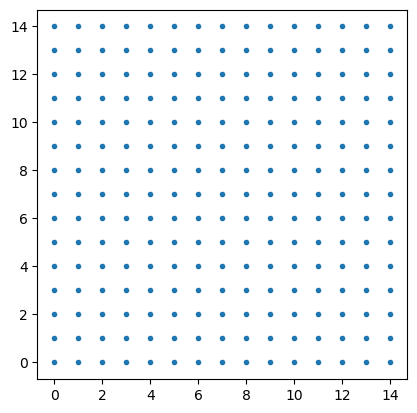

In [6]:
x, y = Bravais2D(theta=90)
plot2D(x, y, sb='.')

### Redes de Bravais en 3D

![Redes de Bravais en 3D](images/Bravais_lattices_3D.png)

> Redes de Bravais en tres dimensiones. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Bravais_lattice)

> Para una visualización tridimensional interactiva, puede consultarse la web de la iniciativa *Dissemination of IT for the Promotion of Materials Science* ([DoITPoMS](https://www.doitpoms.ac.uk/tlplib/crystallography3/systems.php)).

> **Ejercicio**: Para las redes cúbicas centrada en el cuerpo (cI) y centrada en las caras (cF), la celda convencional cúbica de lado $a$ no es primitiva. En ambos casos, la celda primitiva es un romboedro (poliedro formado por seis caras rómbicas). Encuentra los vectores de traslación primitivos, en coordendas cartesianas, y demuestra que el ángulo entre dos aristas adyacentes es $109.5^\circ$ para la cúbica centrada en el cuerpo y $60^\circ$ para la centrada en las caras.

### Celda de Wigner-Seitz

La celda de Wigner-Seitz es una celda primitiva centrada en un nudo de la red de Bravais, que contiene el espacio que está más cerca de ese nudo que de cualquier otro. Para construirla debemos unir el nudo de la red de Bravais con todos sus vecinos (¡ojo! ¡no sólo con los más próximos!) y trazar los planos que bisectan los segmentos de unión entre ellos.

![Celda de Wigner-Seitz](images/Wigner-Seitz.png)

> Ejemplo de construcción de una celda primitiva de Wigner-Seitz en dos dimensiones. Los segmentos azules unen el nudo de la red con sus vecinos y los planos que bisectan se indican en color rojo. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Wigner%E2%80%93Seitz_cell)

![Celdas Wigner-Seitz de la red BCC](images/Truncated_octahedra.jpg)
> Celdas Wigner-Seitz de la red cúbica centrada en el cuerpo. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Wigner%E2%80%93Seitz_cell)

### Red y base

Además de la red de Bravais, para describir completamente la estructura cristalina es necesario indicar su **base**: qué átomos forman la celda y en qué posiciones se encuentran. Como ejemplo, puede pensarse en un mosaico. En la figura se muestra un motivo típico de los mosaicos que se pueden encontrar en la Alhambra de Granada.

> **Ejercicio**: Describe el mosaico como red de Bravais (en 2D) y base.

![Patio de Comares de la Alhambra de Granada](images/Patio_Comares-Alhambra.jpg)
> Patio de Comares de la Alhambra de Granada. Fuente: [Patronato de la Alhambra](https://www.alhambra-patronato.es/edificios-lugares/fachada-de-comares)

![Mosaico nazarí de la Alhambra de Granada](images/alicatado_Alhambra.png)
> Alicatado nazarí, siglo XIV-XV. La Alhambra de Granada. Museo Nacional de Arte Hispano-Musulmán, nº 4610. Fuente: Fernando Hernández Rojo, "Desde el estudio de los elementos de simetría de los mosaicos de la Alhambra hasta la creación de nuevos diseños", (2010) Ed. Universidad de Granada

## 3. Estructuras cristalinas comunes

### Cúbica simple (SCP)

El empaquetamiento cúbico simple (*Simple Cubic Packing*, **SCP**) consiste en una red de Bravais cúbica primitiva (red cP) con un único átomo por celda. La **fracción de empaquetamiento atómico** (**APF**, *Atomic Packing Factor*) es la fracción de volumen ocupada por átomos asumiendo que son *esferas duras* en contacto. En esta estructura hay dos radios atómicos en un lado de la celda, $2r = a$, de donde:
$$\text{APF}_\text{SCP} = \frac{1}{a^3}\frac{4}{3}\pi\left(\frac{a}{2}\right)^3 = \frac{\pi}{6}$$

In [37]:
from math import pi
pi/6

0.5235987755982988

En esta estructura, cada átomo tiene $6$ vecinos más próximos: decimos que el **índice de coordinación** es $6$. También puede ser interesante estudiar el número de segundos vecinos, en este caso, $12$. 

De los elementos, sólo el $\text{Po}$ cristaliza en SCP. Sí que hay muchos materiales cuya red de Bravais subyacente es una cúbica primitiva, sólo que con una base que es poliatómica.

### Cúbica centrada en el cuerpo (BCC)

La estructura BCC es una red cúbica centrada en el cuerpo (cI) con un átomo por celda primitiva (dos átomos por celda convencional cúbica). Para la relación entre el radio atómico y el parámetro de celda (convencional) $a$, puede verse que en una diagonal principal hay 4 radios atómicos, $4r = \sqrt{3} a$. Por tanto:

$$\text{APF}_\text{BCC} = \frac{2}{a^3} \frac{4}{3}\pi\left(\frac{\sqrt{3}}{4}a\right)^3 = \frac{\sqrt{3}\pi}{8}$$

In [41]:
from math import pi, sqrt
sqrt(3)*pi / 8

0.6801747615878316

El índice de coordinación es $8$ para los primeros vecinos y $6$ para los segundos. Como ejemplos de elementos que cristalizan en la estructura BCC tenemos $\text{Li}$, $\text{Na}$, $\text{K}$, $\text{F}$e y $\text{W}$.

### Cúbica centrada en las caras (FCC)

La estructura FCC es una red cúbica centrada en las caras (cF) con un átomo por celda primitiva (cuatro átomos por celda convencional cúbica). Para la relación entre el radio atómico y el parámetro de celda (convencional) $a$, puede verse que en una diagonal de una cara hay 4 radios atómicos, $4r = \sqrt{2}a$. Por tanto:

$$\text{APF}_\text{FCC} = \frac{4}{a^3} \frac{4}{3}\pi\left(\frac{a}{2\sqrt{2}}\right)^3 = \frac{\sqrt{2}\pi}{6}$$

Esta es la mayor fracción de volumen que puede ocupar un empaquetamiento ilimitado de esferas iguales (conjeturado por Kepler en 1611, demostrado por Gauss para una red periódica en 1831 y demostrado por [H.C. Hales](https://arxiv.org/abs/math/9811071v2) para el caso general en 2002). Por este motivo, también se conoce como *empaquetamiento cúbico compacto* (*cubic closest packing*, **CCP**).

In [25]:
from math import pi, sqrt
pi*sqrt(2) / 6

0.740480489693061

El índice de coordinación es $12$, el mayor posible en 3D (conjeturado por Newton, demostrado en 1953 por van der Waerden y Schütte). El número de segundos vecinos, sin embargo, es relativamente bajo, $6$.

Ejemplos de elementos que cristalizan en FCC: $\text{Al}$, $\text{Ca}$, $\text{Ni}$, $\text{Cu}$, $\text{Ag}$, $\text{Au}$ y los gases nobles. 

### Estructura hexagonal compacta (HCP)

La estructura hexagonal compacta (*hexagonal closest packing*, **HCP**) tiene dos átomos por celda primitiva hexagonal (hP): uno en el origen, $(0, 0, 0)$, y otro en el centro de uno de los dos prismas triangulares que forman la celda, $(\tfrac{2}{3}a, \tfrac{1}{3}a, \tfrac{1}{2}c)$.

![Estructura hexagonal compacta](images/Hexagonal_close_packed.png)
> Estructura hexagonal compacta. El volumen mostrado equivale al de tres celdas primitivas y pone de manifiesto la simetría hexagonal. Fuente: [Wikipedia](https://en.m.wikipedia.org/wiki/File:Hexagonal_close_packed.svg)

Para que el empaquetamiento sea realmente *compacto*, la relación entre los parámetros de red $a$ y $c$ tiene que ser:
$$\frac{c}{a} = \sqrt{\frac{8}{3}}$$
> **Ejercicio:** ¡Demuéstralo!

Para esferas iguales, la estructura HCP es igual de eficiente que la FCC, con el mismo APF superior al $72\%$ y también con índice de coordinación $12$. Ambas estructuras pueden construirse superponiendo "capas" de empaquetamiento hexagonal compacto plano (en 2D). Las dos primeras "capas" son iguales en FCC y HCP. La posición relativa de la tercera capa es la que las diferencia. 

![Comparación entre los empaquetamientos compactos cúbico y hexagonal](images/FCC_HCP.png)
> Comparación entre los empaquetamientos compactos con geometría cúbica (estructura FCC o CCP) y hexagonal (estructura HCP). Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Close-packing_of_equal_spheres#/media/File:Cubic_Closest_Packing_(CCP)_and_Hexagonal_Closet_Packing_(HCP).png)

Ejemplos de elementos que cristalizan (aproximadamente) en estructura HCP: $\text{Be}$, $\text{Mg}$, $\text{Ti}$, $\text{Co}$, $\text{Zn}$ y $\text{Cd}$.

### Estructura del diamante

El diamante ($\text{C}$) cristaliza en una estructura formada por la red cúbica centrada en caras (cF) con dos átomos por base, uno en el origen y otro en $a(\tfrac{1}{4}, \tfrac{1}{4}, \tfrac{1}{4})$. Por tanto, en la celda convencional cúbica hay $8$ átomos.

> **Ejercicio:** En un modelo de esferas duras en el que los átomos situados en el origen y en $(\tfrac{1}{4}, \tfrac{1}{4}, \tfrac{1}{4})$ están en contacto, demuestra que la fracción de empaquetamiento de esta estructura es:
$$\frac{\sqrt{3}\pi}{16}$$

In [31]:
from math import sqrt, pi
sqrt(3)*pi/16

0.3400873807939158

![Estructura diamante](images/Diamond_structure.gif)

> Celda convencional de la estructura diamante, resaltando la geometría tetraédrica subyacente. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Orbital_hybridisation)

### Estructuras típicas multicomponente

![sales comunes](images/estructuras_comunes.png)
> Celda convencional de algunos materiales con estructura cristalina multiatómica. Fuente: [Bodner Research Group, Purdue University](https://chemed.chem.purdue.edu/genchem/topicreview/bp/ch13/unitcell.php)

> **Ejercicio:** Con la excepción del rutilo $\text{TiO}_2$, que cristaliza en el sistema tetragonal, el resto de estructuras de la figura superior pertenecen al sistema cúbico. Determina para las estructuras cúbicas mostradas:
> * La red de Bravais y la base.
> * La razón ideal entre radios ionicos que maximiza la fracción de empaquetamiento en un modelo de esferas duras. Ten en cuenta que esto ocurrirá cuando se tenga el mayor número posible de esferas en contacto. En el caso de la perovskita, que involucra tres especies iónicas, puedes asumir que los radios del $\text{Ti}^{4+}$ y el $\text{Ca}^{2+}$ son iguales.
> * La fracción de volumen total ocupada por las esferas en las condiciones del apartado anterior. ¿Se encuentra en algún caso una fracción superior a la correspondiente a las estructuras cúbica compacta y hexagonal compacta? En caso afirmativo, ¿cómo es posible?
> 
>  Por ejemplo, para la estructura del cloruro de cesio tenemos una red cúbica primitiva, con una base formada por un $\text{Cl}^-$ en $(0, 0, 0)$ y un $\text{Cs}^+$ en $(\tfrac{1}{2}, \tfrac{1}{2},\tfrac{1}{2})$; la razón ideal entre radios es $\sqrt{3}-1\approx 0.7321$; y la fracción de volumen máxima ocupada es $72.9\%$, bastante superior a la estructura BCC monoatómica, pero aún inferior a la cúbica compacta (FCC monoatómica).

### Ejercicio: Átomos por celda unidad en el bismuto

El bismuto ($\text{Bi}$) tiene una estructura hexagonal, con $a = 0.4546\,\text{nm}$ y $c = 1.186\,\text{nm}$. La densidad es $9.808\,\text{g}/\text{cm}^3$ y el peso atómico es de $208.98\,\text{g}/\text{mol}$. Determina:

1. El volumen de la celda unidad.
2. ¿Cuántos átomos existen en cada celda unidad?

In [64]:
from math import sqrt
from pint import UnitRegistry

ureg = UnitRegistry(system='cgs')
ureg.formatter.default_format = '.5g~P'
Q_ = ureg.Quantity

a = Q_('0.4546 nm')
c = Q_('1.186 nm')
rho = Q_('9.808 g/cm**3')
M = Q_('208.98 g/mol')

V = a**2 * sqrt(3)/2 * c
V.ito_base_units()
print(f'{V = :}')

N = ureg.N_A * rho * V / M
N.ito_base_units()
print(f'{N = :}')

V = 2.1226×10⁻²² cm³
N = 5.9993


Efectivamente, la celda hexagonal del $\text{Bi}$ contiene $6$ átomos. Sin embargo, al estudiar en detalle las posiciones atómicas encontramos que la estructura del bismuto puede describirse de forma aún más simple con la red de Bravais romboédrica (hR), con $a = 0.474\,\text{nm}$, $\alpha = 57.2^\circ$ y una base de **dos** átomos por celda primitiva, uno en vértice y otro en el centro del romboedro. Obsérvese que la red romboédrica también pertenece al sistema hexagonal.

![estructura del Bi](images/bismuto.png)
> Estructura cristalina del bismuto a $20^\circ\text{C}$, mostrando la simetría hexagonal y la celda primitiva romboédrica (en verde). Fuente: G. Boczkal, P. Pałka, *et al.*, *Materials* **14** 4341 (2021).

## 4. Planos y direcciones en cristales

### Índices de Miller

![ejemplos de planos en estructura cúbica](images/Miller_Indices_Felix_Kling.png)
> Algunos planos en una estructura cúbica, con sus índices de Miller. Autor: Felix Kling. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Miller_index#/media/File:Miller_Indices_Felix_Kling.svg)

> Para una visualización tridimensional interactiva, puede consultarse la web de la [DoITPoMS](
https://www.doitpoms.ac.uk/tlplib/miller_indices/lattice_draw.php).

### Propiedades en planos

Definimos la **densidad de nudos** de una red en el plano de índices $(hkl)$ como el número de nudos de la red contenidos en ese plano por unidad de area. Si se utiliza un modelo atómico, por ejemplo el de esferas duras en contacto, se puede definir la **fracción de area** como la fracción del area del plano que intersecta a los átomos.

> **Ejercicio**: Considera las estructuras cúbicas monoatómicas SC, BCC y FCC y los planos $(100)$, $(110)$ y $(111)$. Para cada caso, calcula la densidad de nudos, dibuja las secciones para el modelo de esferas duras en contacto y calcula la fracción de area ocupada.

In [14]:
# solución (sin detalles de cálculo)
from math import pi, sqrt
estructuras = {'SC': {'radio': 1/2, '{100}': 1, '{110}': 1, '{111}': 1/2},
               'BCC': {'radio': sqrt(3)/4, '{100}': 1, '{110}': 2, '{111}': 1/2},
               'FCC': {'radio': sqrt(2)/4, '{100}': 2, '{110}': 2, '{111}': 2}}
secciones = {'{100}': 1, '{110}': sqrt(2), '{111}': sqrt(3)/2}
for plano in secciones:
    print(f'\t    {plano}', end='')
for red, datos in estructuras.items():
    r = datos['radio']
    print(f'\n{red}', end='')
    for plano, area in secciones.items():
        densidad = datos[plano] / area
        fraccion = densidad * pi * r**2
        print(f'\t{densidad:.3f} ({fraccion :.1%})', end='')

	    {100}	    {110}	    {111}
SC	1.000 (78.5%)	0.707 (55.5%)	0.577 (45.3%)
BCC	1.000 (58.9%)	1.414 (83.3%)	0.577 (34.0%)
FCC	2.000 (78.5%)	1.414 (55.5%)	2.309 (90.7%)

## 5. Defectos en cristales

### Vacantes

La aparición de vacantes está favorecida por el aumento de *entropía*, a pesar de que tiene un coste energético. La fracción de vacantes a una temperatura $T$ dada viene determinada por la *estadística de Boltzmann*:

$$f_v = \frac{N_v}{N} = A e^{\Delta{H_v} / k_BT}$$

Donde $N_v$ es el número de vacantes, $A$ una constante adimensional con valor cercano a la unidad, y $\Delta{H_v}$ es la energía necesaria para crear una vacante (a presión constante).

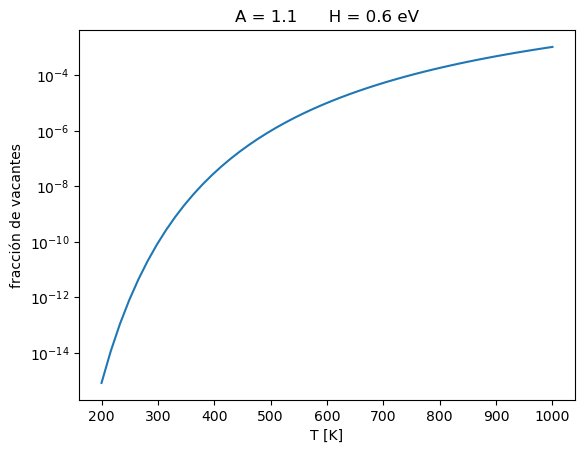

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# constantes
kB = 8.617_333_262E-5 # eV/K

# datos (valores típicos)
A = 1.1 # adim
H = 0.6 # eV

T = np.linspace(200, 1000)
f = A * np.exp(-H / (kB*T))

plt.plot(T, f)
plt.title(f'{A = :}      {H = :} eV')
plt.xlabel('T [K]')
plt.yscale('log')
plt.ylabel('fracción de vacantes')
plt.show()

### Defectos asociados a vacantes

* **Defecto Frenkel**: un átomo intersticial (fuera de su posición habitual en la red) por cada vacante.
* **Defecto Shottky**: una vacante de catión y otra de anión (el material continúa siendo eléctricamente neutro).
* **Antisitios**: en cristales iónicos, un catión y un anión intercambian posiciones.

### Impurezas

Una **impureza** es un átomo de un elemento distinto a los que forma la red cristalina.
* **Sustitucional**: situado en una vacante.
* **Intersticial**: situado en una posición en la que no debería haber ningún átomo.

### Dislocaciones

![Dislocaciones](images/Burgers_Vector_and_dislocations.png)
> Dislocaciones de borde (*edge*) y helicoidal (*screw*), junto con sus vectores de Burger. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Dislocation#/media/File:Burgers_Vector_and_dislocations_(screw_and_edge_type).svg)

## 6. Enlace atómico

### Interacción atómica

En general, la energía de interacción entre dos átomos en un sólido tiene un término atractivo y otro repulsivo, siendo el segundo el dominante a distancias cortas. Ejemplo, **potencial de Lennard-Jones** para $n > m$:

$$\phi(r) = \frac{A}{r^n} - \frac{B}{r^m}$$

Este potencial, con $n = 12$ y $m = 6$, suele utilizarse para interacciones tipo van der Waals y para el enlace metálico.

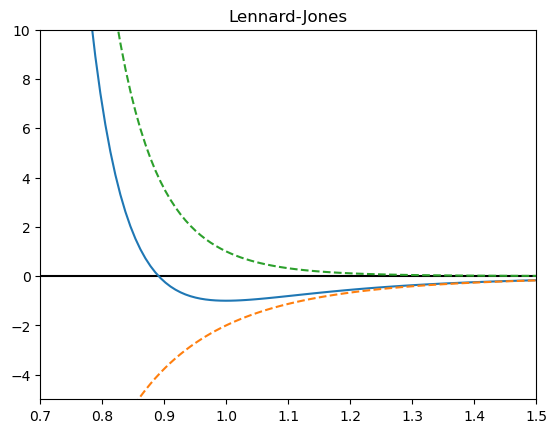

In [83]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# parámetros
A = 2
B = 1
n = 12
m = 6

r = np.linspace(0.7, 1.5, num=100)
phi_atr = - A/r**m
phi_rep = B/r**n
phi = phi_atr + phi_rep

plt.plot((0, 2), (0, 0), 'k')
plt.plot(r, phi)
plt.plot(r, phi_atr, '--')
plt.plot(r, phi_rep, '--')
plt.xlim(0.7, 1.5)
plt.ylim(-5, 10)
plt.title('Lennard-Jones')
plt.show()

Para el enlace convalente es más común utilizar el **potencial de Morse**:
$$U(r)= U_0\left(e^{-2a(r-r_0)}-2e^{-a(r-r_0)}\right)$$
En este caso, además de la dependencia con la distancia, también es relevante el ángulo que forman los enlaces. En otras palabras, *el enlace covalente es direccional*.

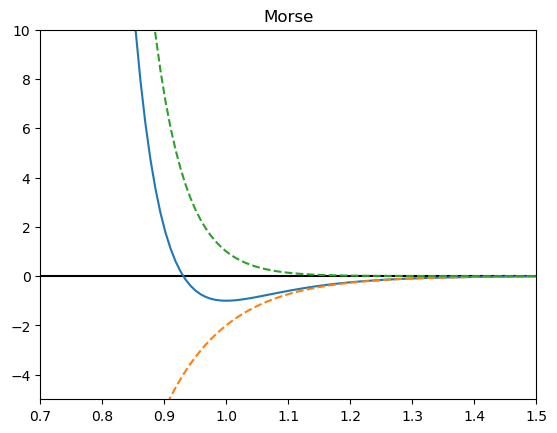

In [88]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# parámetros
U = 1 # profundidad del pozo
a = 10 # factor de alcance
r0 = 1 # posición del mínimo

r = np.linspace(0.7, 1.5, num=100)
phi_atr = -2*U*np.exp(-a*(r-r0))
phi_rep = U*np.exp(-2*a*(r-r0))
phi = phi_atr + phi_rep

plt.plot((0, 2), (0, 0), 'k')
plt.plot(r, phi)
plt.plot(r, phi_atr, '--')
plt.plot(r, phi_rep, '--')
plt.xlim(0.7, 1.5)
plt.ylim(-5, 10)
plt.title('Morse')
plt.show()

Otra expresión común para el potencial de interacción es el potencial **Born-Mayer**, que combina un término atractivo tipo Van der Waals (potencia $-6$), con uno repulsivo tipo exponencial:
$$ U(r) = -\frac{A}{r^6} + C e^{-r/\rho}$$
El resultado tiene una barrera muy intensa para distancia menores que la de equlibrio, por lo que también se conoce como *potencial de esferas duras*.

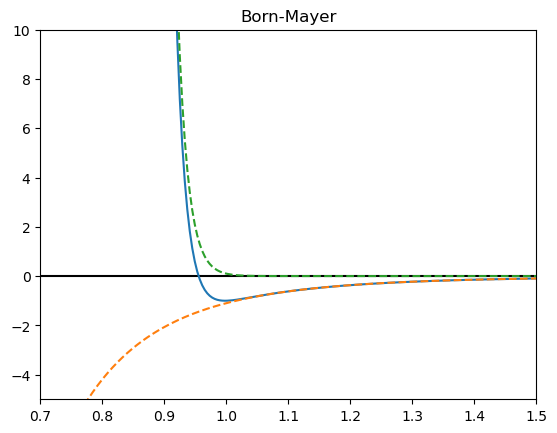

In [85]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt 

# parámetros
f = 0.10     # reducción por repulsión a distancia de equilibrio
A = (1+f)    # profundidad del pozo
rho = f/6    # distancia característica de decaimiento
C = 6*rho*np.exp(1/rho)

r = np.linspace(0.7, 1.5, num=200)
phi_atr = -A / r**6
phi_rep = C*np.exp(-r/rho)
phi = phi_atr + phi_rep

plt.plot((0, 2), (0, 0), 'k')
plt.plot(r, phi)
plt.plot(r, phi_atr, '--')
plt.plot(r, phi_rep, '--')
plt.xlim(0.7, 1.5)
plt.ylim(-5, 10)
plt.title('Born-Mayer')
plt.show()

### Enlace iónico

* Sólo puede darse entre átomos de especies distintas, con muy diferente *afinidad electrónica*, que se encuentran en estado ionizado.
* No hay solapamiento entre las nubes electrónicas de los iones. El término repulsivo es tipo esferas duras.
* La interacción principal es la atracción electrostática entre iones con cargas opuestas.
* Bastante fuerte ($\approx 2\,\text{eV}$ por pareja).
* No direccional. La estructura viene determinada por el cociente entre los radios iónicos de las dos especies.
* Ejemplos: $\text{NaCl}$, $\text{KBr}$, $\text{CaCl}_2$, $\text{KCl}$.
* Como la interacción electrostática tiene un gran alcance, en el cálculo de la energía de cohesión hay que incluir términos correspondientes a muchas capas iónicas de vecinos. La serie resultante (*serie de Madelung*) es condicionalmente convergente.

#### Energía de cohesión: ejemplo de cálculo para el $\text{NaCl}$

1. Ionización del catión y el anión:
* Energía de ionización del catión: $\text{Na} + (5.14\,\text{eV}) \rightarrow \text{Na}^+$
* Afinidad electrónica del anión: $\text{Cl} \rightarrow \text{Cl}^- + (3.61\,\text{eV})$
* Coste energético por pareja: $5.14 - 3.61 = 1.53\,\text{eV}$
2. Ganancia energética por interacción electrostática a la distancia de equilibrio ($r_{eq} = d = 0.282\,\text{nm}$):
$$U_e = -\frac{1}{4\pi\epsilon_0} \frac{e^2}{d} = -5.11\,\text{eV}$$
El proceso es energéticamente favorable, las ``moléculas'' de $\text{NaCl}$ podrían existir. Ganancia por molécula: $E_\text{molecula} = 1.53 - 5.11 = -3.58\,\text{eV}$
3. Ganancia de energía en el sólido:
* Respecto a un $\text{Na}^+$ central, se gana energía por los seis $\text{Cl}^-$ que le rodean (a distancia $d$):
$$E_\text{primeros vecinos} = -6\times\frac{1}{4\pi\epsilon_0}\frac{e^2}{d} \Rightarrow E \approx -6 U_e$$
* Pero ese mismo catión de sodio está rodeado por otros $12$ cationes como segundos vecinos, a una distancia $\sqrt{2}d$, por lo que se *pierde* una energía:
$$U_\text{segundos vecinos} = 12\times\frac{1}{4\pi\epsilon_0}\frac{e^2}{\sqrt{2}d} \Rightarrow E \approx U_e \left(6 - \frac{12}{\sqrt{2}}\right) $$
* Los terceros vecinos del catión de sodio son $8$ aniones de cloro, que contribuyen con otro término de ganancia energética:
$$U_\text{terceros vecinos} = -8\times\frac{1}{4\pi\epsilon_0}\frac{e^2}{\sqrt{3}d} \Rightarrow E \approx U_e \left(6 - \frac{12}{\sqrt{2}} + \frac{8}{\sqrt{3}}\right)$$
* Al añadir más y más términos, se encuentra una serie (condicionalmente) convergente a un valor (*constante de Madelung*) específico para cada estructura. En el caso de la estructura $\text{NaCl}$, se tiene $M_d = 1.747565\dots$, de donde:
$$E = M_d\,U_e \approx -8.92\,\text{eV}$$
* La energía de cohesión suele definirse a partir de los componentes en estado gaseoso no ionizados, por lo que tendríamos $E_\text{cohesion} = -8.92 + 1.53 = -7.39\,\text{eV}$.
* El valor experimental, $E_\text{NaCl} = -6.41\,\text{eV}$ por unidad de fórmula, es menor (en valor absoluto) que el calculado porque en el potencial de interacción entre primeros vecinos hay que incluir la interacción repulsiva de corto alcance de origen cuántico (tipo Born-Mayer $C e^{-r/\rho}$ o tipo Born-Landé $Cr^{-n}$). Esta corrección suele estar entre el $10\%$ y el $15\%$.

In [1]:
from math import sqrt
M = 0
E_par = -5.11 # eV
for i, f in enumerate((6, -12/sqrt(2), 8/sqrt(3), -3, 24/sqrt(5))):
    M += f
    print(f'Con {i+1} términos,\tM = {M:.3f},\tE = {M*E_par:.3f} eV')
M_d = 1.747565
print('...')
print(f'El límite es Md = {M_d},\tE = {M_d * E_par:.3f} eV')

Con 1 términos,	M = 6.000,	E = -30.660 eV
Con 2 términos,	M = -2.485,	E = 12.700 eV
Con 3 términos,	M = 2.134,	E = -10.902 eV
Con 4 términos,	M = -0.866,	E = 4.428 eV
Con 5 términos,	M = 9.867,	E = -50.419 eV
...
El límite es Md = 1.747565,	E = -8.930 eV


### Enlace covalente

* Se produce entre átomos no metálicos idénticos o bastante similares entre sí.
* Muy fuerte ($> 3\,\text{eV}$ por pareja).
* Se produce cuando la superposición entre las nubes electrónicas sólo afecta a los vecinos más próximos. Como consecuencia, es *muy direccional*.
* Sólo puede darse entre orbitales atómicos que no estén completos (electrones desapareados), aunque la presencia de *hibridación de orbitales* puede aumentar el número de coordinación y relajar la asimetría en los ángulos de enlace.
* Produce una acumulación de carga electrónica en la región intermedia entre los dos nucleos (*estado ligante* o *bonding state*).
* Ejemplos: $\text{C}$ (diamante, grafito, grafeno), $\text{Si}$, $\text{Ge}$.

#### Ejemplo de enlace convalente con hibridación: el carbono

El átomo de $\text{C}$ tiene $6$ electrones en total, aunque dos de ellos ocupan el orbital $1s$ que, al estar muy cerca del núcleo, no participa en los enlaces químicos. En el estado fundamental, los otros cuatro electrones llenan el orbital $2s$ y, de forma parcial, dos de los tres orbitales $2p$, por ejemplo los correspondientes a los ejes $X$ e $Y$. Su configuración electrónica sería $1s^2\,2s^2\,2p_x^1\,p_y^1\,p_z^0$, aunque suele escribirse de forma compacta como $[\text{He}]2s^2p^2$. Según esto, se esperaría que un átomo de carbono formase enlaces covalentes con otros dos (valencia $2$), con un ángulo de $90^\circ$. Esto *nunca* se observa entre átomos de carbono porque es energéticamente favorable introducir algún grado de *hibridación* de orbitales.

En primer lugar, uno de los electrones del orbital $2s$ promociona al orbital $2p$ vacío, quedando $1s^2\,2s^1\,2p_x^1\,p_y^1\,p_z^1$ (valencia $4$). A continuación el orbital $2s$ se hibrida con uno, dos o tres de los orbitales $2p$ para formar los orbitales híbridos $sp^1$, $sp^2$ y $sp^3$, respectivamente.

##### Hibridación $sp^3$: el diamante

En el diamante, los átomos de carbono experimentan hibridación $sp^3$. Los cuatro orbitales $2sp^3$ se orientan a ángulos iguales en el espacio de $109.5^\circ$, como los vértices de un tetraedro, y cada uno contiene un único electrón desapareado. Por tanto, cada átomo de carbono forma un enlace covalente con otros cuatro para formar una estructura muy estable (la *estructura diamante* que ya hemos comentado anteriormente).

![Hibridación $sp^3$](images/hibridacion-sp3.png)
> Los cuatro orbitales híbridos $sp^3$ del carbono. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Orbital_hybridisation)

##### Hibridación $sp^2$: el grafeno

En el *grafeno*, los átomos de carbono experimentan hibridación $sp^2$. Eso significa que el orbital $s$ se hibrida con dos de los orbitales $p$, por ejemplo los $p_x$ y $p_y$, mientras que el tercero, $p_z$, continúa inalterado. Los tres orbitales $sp^2$ forman ángulos de $120^\circ$ en un plano y el orbital $p_z$ es perpendicular a ese plano. 


![Hibridación $sp^2$](images/hibridacion-sp2.png)

> Los tres orbitales $sp^2$ (tono oscuro) y el orbital $p_z$ (tono claro) de un átomo de carbono en el grafeno. Fuente: [Wikipedia](https://en.wikipedia.org/wiki/Graphene)

Cada átomo de carbono se une con otros tres en una estructura plana con forma de panel de abeja (red hexagonal con base diatómica). Los enlaces principales se producen entre orbitales híbridos $sp^2$ (enlaces tipo $\sigma$), pero los orbitales $p_z$ también pueden reforzar el enlace interactuando entre sí (enlaces tipo $\pi$).

![Estructura del grafeno](images/Basic_Graphene.png)

> Estructura del grafeno. Obsérvese la distribución aleatoria de los enlaces dobles debido a la interacción $\pi$ entre orbitales $p_z$. Fuente: [Wikipedia](https://commons.wikimedia.org/wiki/File:Basic_Graphene.png)

### Enlace metálico

* Se produce entre átomos metálicos idénticos o bastante similares entre sí.
* Fuerte ($\approx 2\,\text{eV}$ por pareja).
* La superposición entre nubes electrónicas tiene un gran alcance, no se restringe únicamente a los primeros vecinos.
* No es direccional, por lo que favorece un número de coordinación alto (estructuras FCC o HCP).
* Origen cuántico: la deslocalización de los electrones de conducción lleva a una disminución de su energía cinética.

### Enlace de van der Waals

* Atracción débil ($\approx 0.1\,\text{eV}$ por pareja) entre *todas* las distribuciones de carga neutra. Tiene un alcance mayor que otros tipos de enlace.
* No direccional $\rightarrow$ número de coordinación alto.
* Interacción dipolo-dipolo (tanto para dipolos permanentes en moléculas polares como para dipolos inducidos entre apolares).
* Razonablemente bien descrito por potencial de Lennard-Jones con $m = 6$ y $n = 12$.

### Enlace de puente de hidrógeno

* Puede considerarse el caso extremo del enlace iónico en el que una de las especies es un protón ($\text{H}^+$).
* Muy relevante entre moléculas orgánicas de gran tamaño.
* Intensidad intermedia ($\approx 0.5\,\text{eV}$ por pareja).